# t003 — Hybrid ARIMA–GRU trên đủ 6 bộ biến (FS01–FS06)

Mô hình lai kiểu Zhang (2003): ARIMA đơn biến trên giá đồng bắt phần tuyến tính, GRU học phần dư của ARIMA.
Dự báo cuối = dự báo ARIMA + phần dư GRU dự báo. Đối chứng: **Naive** (giá hôm qua), **ARIMA**, **GRU Direct**
(dự báo thẳng giá).

Khung thực nghiệm chung của nhóm: dữ liệu 9 hàng hoá (2016–2026), dự báo 1 phiên, cửa sổ 22,
4 tỷ lệ chia 80/20, 90/10, 92.5/7.5, 95/5, seed 41–45, 6 bộ biến FS01–FS06. Kiến trúc GRU cố định từ trước
(không chọn lại theo test).

- Bộ biến chỉ đổi **đầu vào của GRU**. ARIMA luôn chạy trên Copper → Naive và ARIMA giống nhau ở mọi FS.
- Với FS có Copper, cột Copper trong cửa sổ được thay bằng **phần dư ARIMA**; các biến khác là mức giá MinMax.
- FS03/FS05 không có Copper trong đầu vào GRU, nhưng dự báo vẫn dựa trên ARIMA của Copper (tương tự mô hình Residual
  vẫn cộng lại Copper(t−1)) → không phải "hoàn toàn không dùng lịch sử Copper".
- Chiến lược: Expanding ở cả 4 split; thêm Rolling 756 và Recency (half-life 252) ở 90/10.
  Chiến lược chỉ áp cho GRU; ARIMA fit một lần mỗi split trên toàn bộ phần trước test.

Chạy trên Kaggle (cần TensorFlow, nên bật GPU). Trên máy không có TensorFlow, GRU được thay bằng Ridge **chỉ để
chạy thử ống dữ liệu** — không dùng số đó để báo cáo.

## 1. Cấu hình

In [1]:
import os, glob, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import MinMaxScaler

try:
    import pmdarima
except ImportError:  # Kaggle có thể chưa cài sẵn
    %pip install -q pmdarima
    import pmdarima
from pmdarima import auto_arima
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller

try:
    import tensorflow as tf
    HAS_TF = True
except ImportError:
    from sklearn.linear_model import Ridge
    HAS_TF = False

ON_KAGGLE = os.path.exists('/kaggle/input')
if ON_KAGGLE:
    found = [f for name in ('commodities_9_daily.csv', 'dataset_9_commodities_daily.csv')
             for f in glob.glob(f'/kaggle/input/**/{name}', recursive=True)]
    assert found, ('Không thấy file dữ liệu 9 hàng hoá trong /kaggle/input (Add Input). CSV đang có: '
                   + str(glob.glob('/kaggle/input/**/*.csv', recursive=True)))
    DATA_PATH, OUT_DIR = found[0], '/kaggle/working/t003'
else:
    DATA_PATH, OUT_DIR = '../data/raw/dataset_9_commodities_daily.csv', 'result'  # chạy trong thư mục 'huy task'
os.makedirs(OUT_DIR, exist_ok=True)

TARGET = 'Copper'
FEATURE_SETS = {                       # 6 bộ biến dùng chung của nhóm
    'FS01_CU':         ['Copper'],
    'FS02_PAPER_CU':   ['Copper', 'WTI', 'Gold', 'Silver'],
    'FS03_PAPER_EXO':  ['WTI', 'Gold', 'Silver'],
    'FS04_METALS_CU':  ['Copper', 'Aluminium', 'Tin', 'Silver', 'Gold'],
    'FS05_METALS_EXO': ['Aluminium', 'Tin', 'Silver', 'Gold'],
    'FS06_WTI_CU':     ['Copper', 'Aluminium', 'Tin', 'WTI'],
}
SPLITS = [0.8, 0.9, 0.925, 0.95]
SCHEMES = {r: ['expanding'] for r in SPLITS}
SCHEMES[0.9] += ['rolling_756', 'recency_weighted']    # 2 chiến lược phụ chỉ ở 90/10
LOOKBACK = 22
SEEDS = [41, 42, 43, 44, 45]
EPOCHS, PATIENCE, BATCH, LR = 65, 9, 64, 1e-3          # cấu hình GRU chung của nhóm
VAL_FRAC = 0.10        # validation = 10% cuối phần trước test (val_start = int(split·0.9))
ROLL_WINDOW, HALF_LIFE = 756, 252
WARMUP = 30            # bỏ vài phiên đầu: dự báo in-sample của ARIMA lúc đầu chưa ổn định
DM_LAGS = 5            # Newey–West lag 5 + hiệu chỉnh HLN, như nhóm
QUICK = False          # True: 1 seed, 3 epoch — chỉ để thử notebook
if QUICK:
    SEEDS, EPOCHS, PATIENCE = [42], 3, 2
if not HAS_TF:
    SEEDS = [42]       # Ridge không phụ thuộc seed

n_fits = sum(len(s) for s in SCHEMES.values()) * len(FEATURE_SETS) * len(SEEDS) * 2
print('TensorFlow:', HAS_TF, '| Kaggle:', ON_KAGGLE, '| data:', DATA_PATH)
if ON_KAGGLE and not (HAS_TF and tf.config.list_physical_devices('GPU')):
    print('CẢNH BÁO: chưa có GPU (Settings → Accelerator → GPU), chạy CPU sẽ rất lâu')
print('Số lần train GRU:', n_fits)

Note: you may need to restart the kernel to use updated packages.


I0000 00:00:1795361018.821642      15 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795361033.719338      15 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow: True | Kaggle: True | data: /kaggle/input/datasets/huyphan726/copper-9-commodities/commodities_9_daily.csv
Số lần train GRU: 360


## 2. Dữ liệu

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=['Date']).sort_values('Date').reset_index(drop=True)
used = sorted({c for v in FEATURE_SETS.values() for c in v} | {TARGET})
assert set(used) <= set(df.columns), set(used) - set(df.columns)
assert not df[used].isna().any().any(), 'Có ô trống trong các cột dùng'
assert not df['Date'].duplicated().any()
y = df[TARGET].to_numpy(float)
dates = df['Date'].to_numpy()
n = len(y)
print(n, 'phiên,', df['Date'].min().date(), '->', df['Date'].max().date())

for name, s in [('Mức giá', y), ('Sai phân bậc 1', np.diff(y))]:
    stat, p = adfuller(s)[:2]
    print(f'ADF {name}: stat={stat:.3f}, p={p:.4f} ->', 'dừng' if p < 0.05 else 'không dừng')

2710 phiên, 2016-01-13 -> 2026-11-13
ADF Mức giá: stat=-0.846, p=0.8053 -> không dừng
ADF Sai phân bậc 1: stat=-22.980, p=0.0000 -> dừng


/tmp/ipykernel_15/3395980785.py:12: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p = adfuller(s)[:2]
/tmp/ipykernel_15/3395980785.py:12: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p = adfuller(s)[:2]


## 3. Hàm dùng chung

- `metrics`: MAE, RMSE, MAPE, R², **DA** (dấu của Δ dự báo = dấu của Δ thật, so với giá hôm qua) và p-value kiểm định nhị thức DA so với 50%. Naive (Δ dự báo = 0) không có DA.
- `dm_test`: Diebold–Mariano, `d_t = |e_model|^p − |e_naive|^p`, phương sai HAC Bartlett lag 5, hiệu chỉnh HLN,
  p-value theo t(n−1). `DM < 0` = sai số nhỏ hơn Naive.
- `arima_one_step`: chọn (p,d,q) bằng `auto_arima` **chỉ trên phần trước test**, giữ nguyên tham số, chạy bộ lọc
  trên cả chuỗi → dự báo tại t chỉ dùng dữ liệu tới t−1.
- `split_points`: điểm chia chung — `split = int(n·r)`, `val_start = int(split·0.9)`,
  rolling bắt đầu từ `val_start − 756`. Scaler chỉ fit trên `[fit_start, val_start)`.
- `run_fs`: train GRU Direct và GRU học phần dư cho một FS × split × chiến lược × seed.

In [3]:
def metrics(actual, pred, prev):
    err = actual - pred
    out = {'MAE': np.mean(np.abs(err)), 'RMSE': np.sqrt(np.mean(err ** 2)),
           'MAPE (%)': 100 * np.mean(np.abs(err / actual)),
           'R2': 1 - np.sum(err ** 2) / np.sum((actual - actual.mean()) ** 2),
           'DA (%)': np.nan, 'p DA': np.nan}
    if not np.allclose(pred, prev):           # Naive dự báo "không đổi" → DA không có nghĩa
        hit = np.sign(pred - prev) == np.sign(actual - prev)
        out['DA (%)'] = 100 * hit.mean()
        out['p DA'] = stats.binomtest(int(hit.sum()), len(hit), 0.5).pvalue
    return out


def dm_test(actual, pred, base, power=1):
    d = np.abs(actual - pred) ** power - np.abs(actual - base) ** power
    if np.allclose(d, 0):
        return np.nan, np.nan                 # hai dự báo trùng nhau, không kiểm định được
    m = len(d)
    d0 = d - d.mean()
    var = d0 @ d0 / m
    for k in range(1, DM_LAGS + 1):
        var += 2 * (1 - k / (DM_LAGS + 1)) * (d0[k:] @ d0[:-k]) / m
    stat = d.mean() / np.sqrt(var / m) * np.sqrt((m - 1) / m)   # HLN với h = 1
    return stat, 2 * stats.t.sf(abs(stat), m - 1)


def arima_one_step(y, train_end):
    am = auto_arima(y[:train_end], test='adf', seasonal=False, stepwise=True,
                    suppress_warnings=True, error_action='ignore')
    order = am.order
    trend = ('t' if order[1] == 1 else 'c') if am.with_intercept else 'n'   # d=1: hằng số = drift
    if order[1] >= 2:
        trend = 'n'
    res = ARIMA(y[:train_end], order=order, trend=trend).fit()
    pred = res.apply(y).get_prediction().predicted_mean   # tham số fit trên train, không ước lượng lại
    return pred, order, trend


def split_points(r, scheme):
    split = int(n * r)
    val_start = int(split * (1 - VAL_FRAC))
    fit_start = max(0, val_start - ROLL_WINDOW) if scheme == 'rolling_756' else 0
    return split, val_start, fit_start


def make_xy(F, target, lo, split, val_start):
    # mẫu tại phiên t: đầu vào F[t-22:t] (chỉ tới t−1), nhãn target[t]
    def block(a, b):
        idx = np.arange(max(a, lo + LOOKBACK), b)
        X = np.stack([F[t - LOOKBACK:t] for t in idx]).astype('float32')
        return X, target[idx].astype('float32'), idx
    return block(lo, val_start), block(val_start, split), block(split, n)


def sample_weights(m, scheme):
    if scheme != 'recency_weighted':
        return None
    w = 0.5 ** (np.arange(m - 1, -1, -1) / HALF_LIFE)    # mẫu mới nhất trọng số lớn nhất
    return (w / w.mean()).astype('float32')


def fit_predict(tr, va, te, w, seed):
    if not HAS_TF:   # chỉ để chạy thử trên máy
        model = Ridge(alpha=1.0).fit(tr[0].reshape(len(tr[0]), -1), tr[1], sample_weight=w)
        return model.predict(te[0].reshape(len(te[0]), -1))
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    L = tf.keras.layers
    model = tf.keras.Sequential([           # GRU 2 lớp 64→32
        L.Input(shape=tr[0].shape[1:]),
        L.GRU(64, return_sequences=True), L.Dropout(0.2),
        L.GRU(32), L.Dropout(0.2),
        L.Dense(16, activation='relu'), L.Dense(1),
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(LR), loss='mse')
    stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=PATIENCE,
                                            restore_best_weights=True)
    model.fit(tr[0], tr[1], sample_weight=w, validation_data=(va[0], va[1]), epochs=EPOCHS,
              batch_size=BATCH, shuffle=False, verbose=0, callbacks=[stop])
    return model.predict(te[0], verbose=0).ravel()


def run_fs(fs, r, scheme, seed, resid, arima_pred):
    cols = FEATURE_SETS[fs]
    split, val_start, fit_start = split_points(r, scheme)

    # GRU Direct: đầu vào = mức giá các biến của FS, nhãn = giá Copper
    xs = MinMaxScaler().fit(df[cols].iloc[fit_start:val_start])
    ys = MinMaxScaler().fit(df[[TARGET]].iloc[fit_start:val_start])
    tr, va, te = make_xy(xs.transform(df[cols]), ys.transform(df[[TARGET]]).ravel(),
                         fit_start, split, val_start)
    assert te[2][0] == split and te[2][-1] == n - 1
    z = fit_predict(tr, va, te, sample_weights(len(tr[1]), scheme), seed)
    direct = ys.inverse_transform(z.reshape(-1, 1)).ravel()

    # Hybrid: cột Copper thay bằng phần dư ARIMA; nhãn = phần dư ARIMA
    lo = max(fit_start, WARMUP)
    H = df[cols].copy()
    if TARGET in cols:
        H[TARGET] = resid
    hs = MinMaxScaler().fit(H.iloc[lo:val_start])
    rs = MinMaxScaler().fit(resid[lo:val_start, None])
    tr, va, te = make_xy(hs.transform(H), rs.transform(resid[:, None]).ravel(), lo, split, val_start)
    z = fit_predict(tr, va, te, sample_weights(len(tr[1]), scheme), seed)
    hybrid = arima_pred[te[2]] + rs.inverse_transform(z.reshape(-1, 1)).ravel()
    return direct, hybrid


def row(r, scheme, fs, model, seed, actual, pred, prev):
    dm1, p1 = dm_test(actual, pred, prev, 1)
    dm2, p2 = dm_test(actual, pred, prev, 2)
    return {'Split': f'{r:g}/{1 - r:.3g}', 'Scheme': scheme, 'FS': fs, 'Mô hình': model, 'Seed': seed,
            'Test': len(actual), **metrics(actual, pred, prev),
            'DM L1': dm1, 'p L1': p1, 'DM L2': dm2, 'p L2': p2}

Tự kiểm tra: ARIMA không dùng giá của chính phiên cần dự báo; DM, DA, trọng số recency và điểm chia đúng.

In [4]:
_te = int(n * SPLITS[0])
_p1, _, _ = arima_one_step(y, _te)
_y2 = y.copy(); _y2[-1] *= 1.5
_p2, _, _ = arima_one_step(_y2, _te)
assert np.isclose(_p1[-1], _p2[-1]), 'ARIMA dùng giá của chính phiên cần dự báo!'
assert np.allclose(_p1[:-1], _p2[:-1])
print('OK: dự báo ARIMA tại t chỉ dùng dữ liệu tới t-1')

_rng = np.random.default_rng(0)
_a, _b = y[-300:], y[-301:-1]
_s, _p = dm_test(_a, _b + _rng.normal(0, 0.2, 300), _b)
assert _s > 0 and _p < 0.01, (_s, _p)
assert np.isnan(dm_test(_a, _b, _b)[0])
print(f'OK: DM phát hiện dự báo kém hơn (stat={_s:.1f}, p={_p:.1e})')

assert np.isnan(metrics(_a, _b, _b)['DA (%)'])                        # Naive: không có DA
_m = metrics(_a, _a + 1e-9 * np.sign(_a - _b), _b)                    # đoán đúng hướng mọi phiên
assert _m['DA (%)'] == 100 and _m['p DA'] < 1e-6, _m
_w = sample_weights(1000, 'recency_weighted')
assert np.isclose(_w.mean(), 1) and np.argmax(_w) == 999 and np.isclose(_w[-1] / _w[-1 - HALF_LIFE], 2)
_s, _v, _f = split_points(0.9, 'rolling_756')
assert _v - _f == ROLL_WINDOW and _s == int(n * 0.9) and split_points(0.9, 'expanding')[2] == 0
print('OK: DA, trọng số recency, điểm chia')

OK: dự báo ARIMA tại t chỉ dùng dữ liệu tới t-1
OK: DM phát hiện dự báo kém hơn (stat=12.3, p=1.4e-28)
OK: DA, trọng số recency, điểm chia


## 4. Chạy

Mỗi split: ARIMA fit một lần (dùng chung cho mọi FS và chiến lược). Mỗi FS × chiến lược × seed: train GRU Direct
và GRU phần dư. Kết quả lưu dần vào `results_by_seed.csv` (phòng phiên Kaggle bị ngắt) và
`predictions_<FS>_<split>_<chiến lược>.csv` (từng phiên, từng seed — dùng cho kiểm định DM chéo giữa các phương pháp).

In [5]:
rows, t0, arima_info = [], time.time(), {}
for r in SPLITS:
    split = int(n * r)
    test_idx = np.arange(split, n)
    actual, prev = y[test_idx], y[test_idx - 1]
    arima_pred, order, trend = arima_one_step(y, split)
    resid = y - arima_pred
    arima_info[f'{r:g}'] = f'ARIMA{order} trend={trend}'
    base = {'Naive': prev, 'ARIMA': arima_pred[test_idx]}
    for name, p in base.items():
        rows.append(row(r, '—', '—', name, None, actual, p, prev))
    print(f'split {r:g}: ARIMA{order} trend={trend}, test={len(test_idx)}')

    for scheme in SCHEMES[r]:
        for fs in FEATURE_SETS:
            preds = {'Date': dates[test_idx], 'Actual': actual, **base}
            for seed in SEEDS:
                d, h = run_fs(fs, r, scheme, seed, resid, arima_pred)
                preds[f'GRU Direct_s{seed}'], preds[f'Hybrid_s{seed}'] = d, h
                rows += [row(r, scheme, fs, 'GRU Direct', seed, actual, d, prev),
                         row(r, scheme, fs, 'Hybrid ARIMA-GRU', seed, actual, h, prev)]
            pd.DataFrame(preds).to_csv(f'{OUT_DIR}/predictions_{fs}_{r:g}_{scheme}.csv', index=False)
            print(f'  {scheme:<16} {fs:<16} xong | {(time.time() - t0) / 60:.1f} phút', flush=True)
        pd.DataFrame(rows).to_csv(f'{OUT_DIR}/results_by_seed.csv', index=False)

results = pd.DataFrame(rows)   # mỗi dòng = 1 mô hình × FS × chiến lược × seed × split
results.to_csv(f'{OUT_DIR}/results_by_seed.csv', index=False)
print(arima_info)

split 0.8: ARIMA(0, 1, 0) trend=n, test=542


E0000 00:00:1795361047.181487      15 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


  expanding        FS01_CU          xong | 3.2 phút
  expanding        FS02_PAPER_CU    xong | 6.8 phút
  expanding        FS03_PAPER_EXO   xong | 11.9 phút
  expanding        FS04_METALS_CU   xong | 15.7 phút
  expanding        FS05_METALS_EXO  xong | 20.3 phút
  expanding        FS06_WTI_CU      xong | 24.2 phút


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


split 0.9: ARIMA(0, 1, 0) trend=n, test=271
  expanding        FS01_CU          xong | 30.4 phút
  expanding        FS02_PAPER_CU    xong | 34.6 phút
  expanding        FS03_PAPER_EXO   xong | 39.3 phút
  expanding        FS04_METALS_CU   xong | 44.2 phút
  expanding        FS05_METALS_EXO  xong | 48.2 phút
  expanding        FS06_WTI_CU      xong | 55.2 phút
  rolling_756      FS01_CU          xong | 59.4 phút
  rolling_756      FS02_PAPER_CU    xong | 62.5 phút
  rolling_756      FS03_PAPER_EXO   xong | 65.5 phút
  rolling_756      FS04_METALS_CU   xong | 68.8 phút
  rolling_756      FS05_METALS_EXO  xong | 71.3 phút
  rolling_756      FS06_WTI_CU      xong | 75.7 phút
  recency_weighted FS01_CU          xong | 82.3 phút
  recency_weighted FS02_PAPER_CU    xong | 89.3 phút
  recency_weighted FS03_PAPER_EXO   xong | 93.8 phút
  recency_weighted FS04_METALS_CU   xong | 99.8 phút
  recency_weighted FS05_METALS_EXO  xong | 105.3 phút
  recency_weighted FS06_WTI_CU      xong | 109.6 phút


## 5. Tổng hợp qua seed

- Số liệu trung bình qua seed (Naive, ARIMA không có seed). `ΔMAE vs Naive (%)`: âm = tốt hơn Naive.
- `Thắng/Thua p<0.05`: số seed mà DM có ý nghĩa 5% theo chiều tốt hơn / kém hơn Naive.
- `Seed DA p<0.05`: số seed có DA khác 50% có ý nghĩa (kiểm định nhị thức).
- Lưu ý khi đọc: 4 tập test lồng nhau (95/5 ⊂ 92.5/7.5 ⊂ 90/10 ⊂ 80/20) nên không phải 4 bằng chứng độc lập;
  chạy nhiều phép DM thì vài lần p<0.05 có thể chỉ do ngẫu nhiên.

In [6]:
for L in ('L1', 'L2'):
    results[f'Thắng {L}'] = (results[f'p {L}'] < 0.05) & (results[f'DM {L}'] < 0)
    results[f'Thua {L}'] = (results[f'p {L}'] < 0.05) & (results[f'DM {L}'] > 0)
results['DA sig'] = results['p DA'] < 0.05

summary = (results.groupby(['Split', 'Scheme', 'FS', 'Mô hình'], sort=False)
           .agg(MAE=('MAE', 'mean'), MAE_std=('MAE', 'std'), RMSE=('RMSE', 'mean'),
                **{'MAPE (%)': ('MAPE (%)', 'mean'), 'DA (%)': ('DA (%)', 'mean')}, R2=('R2', 'mean'),
                **{'DM L1 (tb)': ('DM L1', 'mean'), 'p L1 (tb)': ('p L1', 'mean'),
                   'Thắng p<0.05 L1': ('Thắng L1', 'sum'), 'Thua p<0.05 L1': ('Thua L1', 'sum'),
                   'DM L2 (tb)': ('DM L2', 'mean'), 'p L2 (tb)': ('p L2', 'mean'),
                   'Thắng p<0.05 L2': ('Thắng L2', 'sum'), 'Thua p<0.05 L2': ('Thua L2', 'sum'),
                   'Seed DA p<0.05': ('DA sig', 'sum'), 'Số seed': ('MAE', 'count')})
           .reset_index())
naive_mae = summary[summary['Mô hình'] == 'Naive'].set_index('Split')['MAE']
summary.insert(4, 'ΔMAE vs Naive (%)', 100 * (summary['MAE'] / summary['Split'].map(naive_mae) - 1))
summary.to_csv(f'{OUT_DIR}/results.csv', index=False)
summary[summary['Mô hình'].isin(['Naive', 'ARIMA'])].round(6)

,Split,Scheme,FS,Mô hình,ΔMAE vs Naive (%),MAE,MAE_std,RMSE,MAPE (%),DA (%),...,DM L1 (tb),p L1 (tb),Thắng p<0.05 L1,Thua p<0.05 L1,DM L2 (tb),p L2 (tb),Thắng p<0.05 L2,Thua p<0.05 L2,Seed DA p<0.05,Số seed
0,0.8/0.2,—,—,Naive,0.000000,0.069001,NaN,0.108000,1.289379,NaN,...,NaN,NaN,0,0,NaN,NaN,0,0,0,1
1,0.8/0.2,—,—,ARIMA,0.000000,0.069001,NaN,0.108000,1.289379,NaN,...,NaN,NaN,0,0,NaN,NaN,0,0,0,1
14,0.9/0.1,—,—,Naive,0.000000,0.077077,NaN,0.101033,1.277697,NaN,...,NaN,NaN,0,0,NaN,NaN,0,0,0,1
15,0.9/0.1,—,—,ARIMA,0.000000,0.077077,NaN,0.101033,1.277697,NaN,...,NaN,NaN,0,0,NaN,NaN,0,0,0,1
52,0.925/0.075,—,—,Naive,0.000000,0.075116,NaN,0.098399,1.208127,NaN,...,NaN,NaN,0,0,NaN,NaN,0,0,0,1
53,0.925/0.075,—,—,ARIMA,-0.745757,0.074556,NaN,0.098132,1.198805,52.450980,...,-1.149487,0.251708,0,0,-0.480035,0.631719,0,0,0,1
66,0.95/0.05,—,—,Naive,0.000000,0.072799,NaN,0.096612,1.130180,NaN,...,NaN,NaN,0,0,NaN,NaN,0,0,0,1
67,0.95/0.05,—,—,ARIMA,-0.306790,0.072576,NaN,0.097057,1.126422,50.735294,...,-0.312408,0.755212,0,0,0.901066,0.369158,0,0,0,1


### Expanding: ΔMAE so với Naive (%) theo FS × split, kèm trung bình 6 FS (không chỉ lấy FS tốt nhất)

In [7]:
exp = summary[summary['Scheme'] == 'expanding']
tables = {}
for m in ['Hybrid ARIMA-GRU', 'GRU Direct']:
    for val in ['ΔMAE vs Naive (%)', 'DA (%)', 'Thắng p<0.05 L1']:
        t = exp[exp['Mô hình'] == m].pivot(index='FS', columns='Split', values=val)
        if val == 'Thắng p<0.05 L1':
            t.loc['Tổng'] = t.sum()
        else:
            t.loc['TB 6 FS'] = t.mean()
        tables[(m, val)] = t
        print(f'\n{m} — {val}')
        display(t.round(3))


Hybrid ARIMA-GRU — ΔMAE vs Naive (%)


Split,0.8/0.2,0.9/0.1,0.925/0.075,0.95/0.05
FS,,,,
FS01_CU,5.433,0.480,-0.483,0.062
FS02_PAPER_CU,13.574,5.215,1.823,1.738
FS03_PAPER_EXO,20.492,8.130,15.715,13.877
FS04_METALS_CU,9.207,6.197,1.699,3.742
FS05_METALS_EXO,5.948,4.716,1.869,0.483
FS06_WTI_CU,4.079,1.769,4.941,3.157
TB 6 FS,9.789,4.418,4.261,3.843



Hybrid ARIMA-GRU — DA (%)


Split,0.8/0.2,0.9/0.1,0.925/0.075,0.95/0.05
FS,,,,
FS01_CU,44.686,48.708,52.647,53.971
FS02_PAPER_CU,49.742,50.111,53.431,50.441
FS03_PAPER_EXO,51.993,49.963,50.490,50.882
FS04_METALS_CU,47.417,49.520,52.059,50.000
FS05_METALS_EXO,51.439,51.070,52.353,52.206
FS06_WTI_CU,48.266,48.118,50.000,44.853
TB 6 FS,48.924,49.582,51.830,50.392



Hybrid ARIMA-GRU — Thắng p<0.05 L1


Split,0.8/0.2,0.9/0.1,0.925/0.075,0.95/0.05
FS,,,,
FS01_CU,0,0,0,0
FS02_PAPER_CU,0,0,0,0
FS03_PAPER_EXO,0,0,0,0
FS04_METALS_CU,0,0,0,0
FS05_METALS_EXO,0,0,0,0
FS06_WTI_CU,0,0,0,0
Tổng,0,0,0,0


... (2 outputs left out)


GRU Direct — DA (%)


Split,0.8/0.2,0.9/0.1,0.925/0.075,0.95/0.05
FS,,,,
FS01_CU,50.074,46.494,46.667,45.441
FS02_PAPER_CU,48.635,51.218,49.216,45.147
FS03_PAPER_EXO,49.557,50.111,47.941,47.500
FS04_METALS_CU,49.299,49.815,48.137,45.294
FS05_METALS_EXO,51.697,50.996,48.333,47.353
FS06_WTI_CU,50.332,47.011,46.667,45.294
TB 6 FS,49.932,49.274,47.827,46.005



GRU Direct — Thắng p<0.05 L1


Split,0.8/0.2,0.9/0.1,0.925/0.075,0.95/0.05
FS,,,,
FS01_CU,0,0,0,0
FS02_PAPER_CU,0,0,0,0
FS03_PAPER_EXO,0,0,0,0
FS04_METALS_CU,0,0,0,0
FS05_METALS_EXO,0,0,0,0
FS06_WTI_CU,0,0,0,0
Tổng,0,0,0,0


### 90/10: so sánh 3 chiến lược (ΔMAE so với Naive, %)

In [8]:
s90 = summary[(summary['Split'] == '0.9/0.1') & summary['Mô hình'].isin(['Hybrid ARIMA-GRU', 'GRU Direct'])]
t90 = s90.pivot_table(index='FS', columns=['Mô hình', 'Scheme'], values='ΔMAE vs Naive (%)')
t90.columns = [f'{m} | {s}' for m, s in t90.columns]
t90.loc['TB 6 FS'] = t90.mean()
t90.to_csv(f'{OUT_DIR}/schemes_90_10.csv')
t90.round(3)

,GRU Direct | expanding,GRU Direct | recency_weighted,GRU Direct | rolling_756,Hybrid ARIMA-GRU | expanding,Hybrid ARIMA-GRU | recency_weighted,Hybrid ARIMA-GRU | rolling_756
FS,,,,,,
FS01_CU,338.640,229.742,158.403,0.480,0.316,1.942
FS02_PAPER_CU,276.545,251.001,434.183,5.215,9.784,17.362
FS03_PAPER_EXO,547.593,675.611,630.248,8.130,16.959,101.225
FS04_METALS_CU,280.430,296.416,336.017,6.197,5.251,16.946
FS05_METALS_EXO,632.459,496.030,472.980,4.716,2.337,46.951
FS06_WTI_CU,297.693,453.363,223.294,1.769,2.420,10.281
TB 6 FS,395.560,400.360,375.854,4.418,6.178,32.451


### Bảng theo khuôn tổng hợp chung của nhóm (90/10 Expanding)

In [9]:
q = exp[exp['Split'] == '0.9/0.1']
out = []
for m, objective in [('Hybrid ARIMA-GRU', 'Residual'), ('GRU Direct', 'Direct')]:
    g = q[q['Mô hình'] == m]
    rec = {'member': 'Huy (PP5)', 'method': f'{m} ({len(SEEDS)}-seed mean)', 'objective': objective}
    for _, x in g.iterrows():
        k = x['FS'][:4]
        rec |= {f'{k}_MAE': x['MAE'], f'{k}_RMSE': x['RMSE'], f'{k}_DA_pct': x['DA (%)'],
                f'{k}_Skill_vs_Naive_pct': -x['ΔMAE vs Naive (%)']}
    rec |= {'Mean_MAE_across_FS': g['MAE'].mean(), 'Best_FS_MAE': g['MAE'].min()}
    out.append(rec)
group_fmt = pd.DataFrame(out)
group_fmt.to_csv(f'{OUT_DIR}/group_format_90_10.csv', index=False)
group_fmt.round(5)

,member,method,objective,FS01_MAE,FS01_RMSE,FS01_DA_pct,FS01_Skill_vs_Naive_pct,FS02_MAE,FS02_RMSE,FS02_DA_pct,...,FS05_MAE,FS05_RMSE,FS05_DA_pct,FS05_Skill_vs_Naive_pct,FS06_MAE,FS06_RMSE,FS06_DA_pct,FS06_Skill_vs_Naive_pct,Mean_MAE_across_FS,Best_FS_MAE
0,Huy (PP5),Hybrid ARIMA-GRU (5-seed mean),Residual,0.07745,0.10142,48.70849,-0.48001,0.08110,0.10539,50.11070,...,0.08071,0.10560,51.07011,-4.71584,0.07844,0.10234,48.11808,-1.76857,0.08048,0.07745
1,Huy (PP5),GRU Direct (5-seed mean),Direct,0.33809,0.37233,46.49446,-338.64002,0.29023,0.35037,51.21771,...,0.56456,0.67938,50.99631,-632.45854,0.30653,0.35102,47.01107,-297.69298,0.38196,0.29023


## 6. Biểu đồ

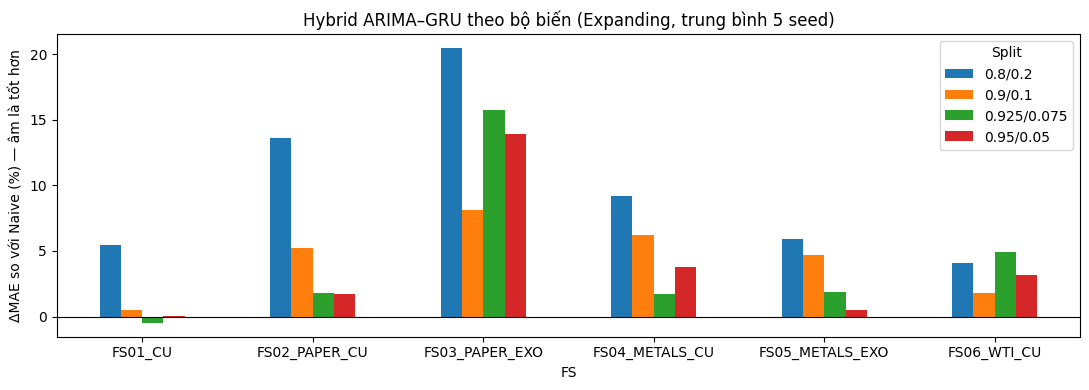

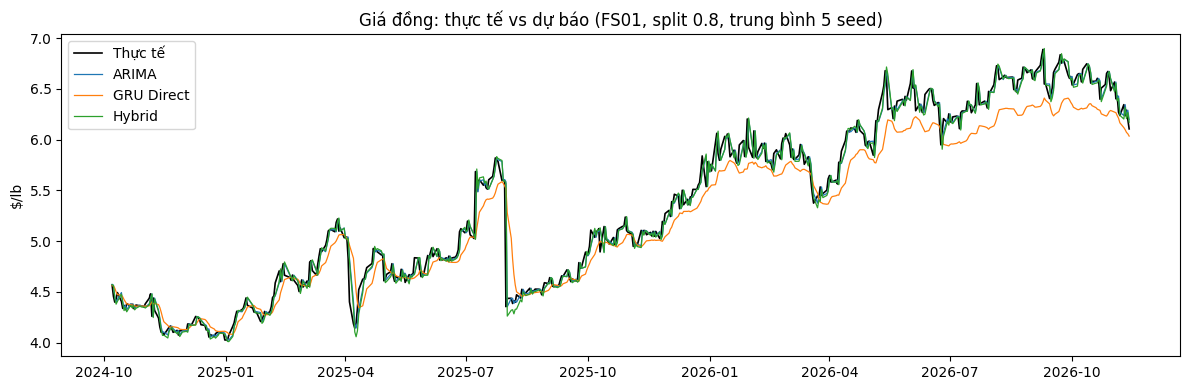

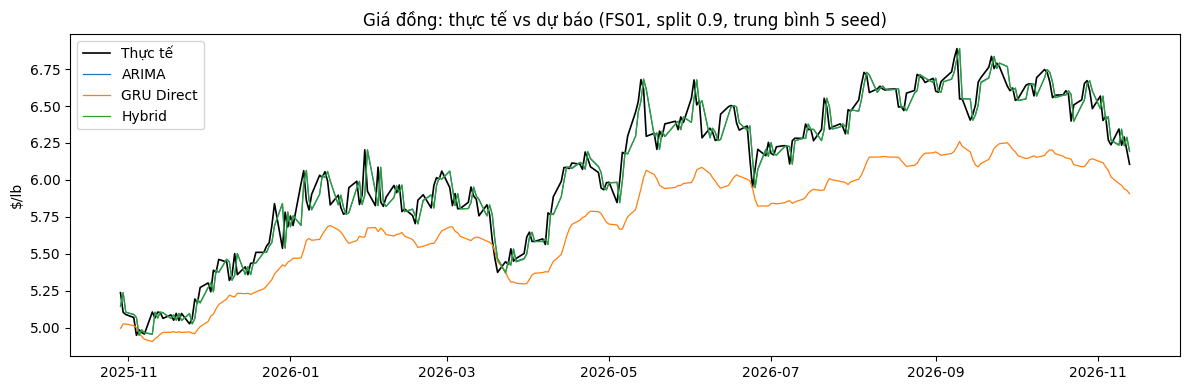

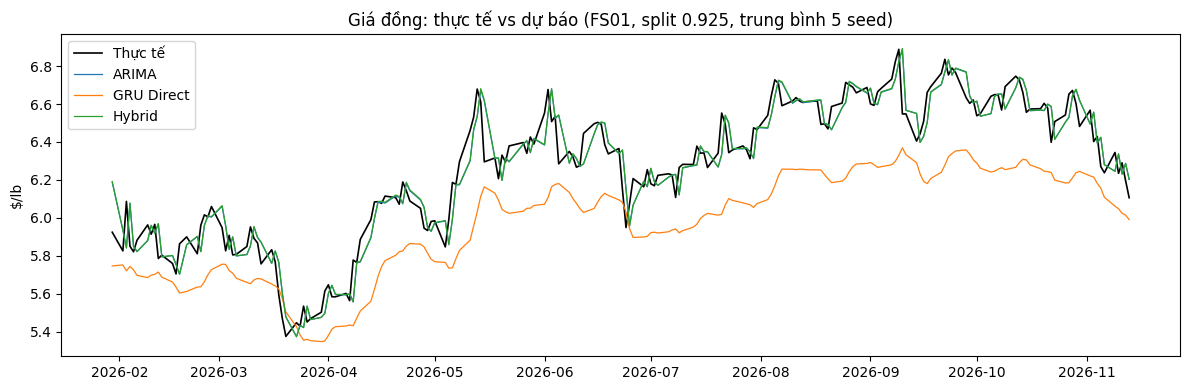

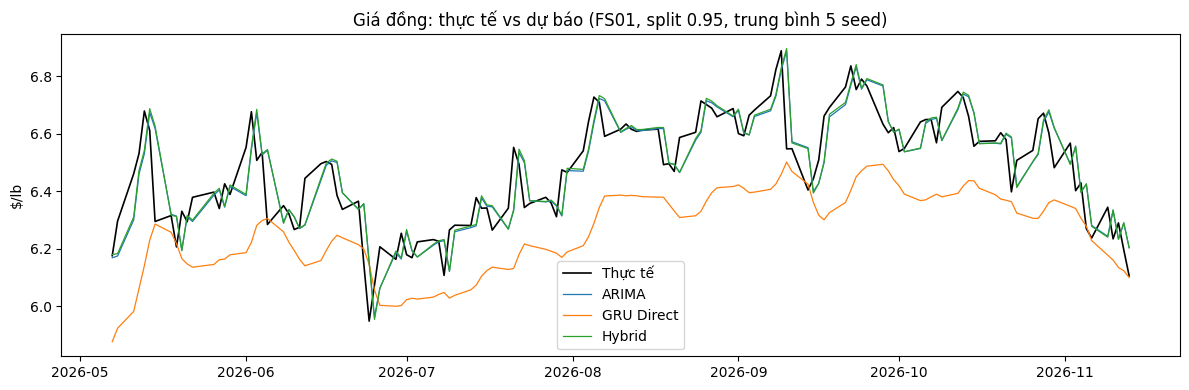

Đã lưu kết quả vào /kaggle/working/t003


In [10]:
# ΔMAE của Hybrid theo FS ở 4 split (Expanding)
t = tables[('Hybrid ARIMA-GRU', 'ΔMAE vs Naive (%)')].drop(index='TB 6 FS')
ax = t.plot.bar(figsize=(11, 4), rot=0)
ax.axhline(0, color='black', lw=0.8)
ax.set_ylabel('ΔMAE so với Naive (%) — âm là tốt hơn')
ax.set_title(f'Hybrid ARIMA–GRU theo bộ biến (Expanding, trung bình {len(SEEDS)} seed)')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/hybrid_delta_mae_by_fs.png', dpi=150); plt.show()

# Thực tế vs dự báo, FS01, mỗi split
for r in SPLITS:
    p = pd.read_csv(f'{OUT_DIR}/predictions_FS01_CU_{r:g}_expanding.csv', parse_dates=['Date'])
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(p['Date'], p['Actual'], color='black', lw=1.2, label='Thực tế')
    ax.plot(p['Date'], p['ARIMA'], lw=0.9, label='ARIMA')
    for name in ['GRU Direct', 'Hybrid']:
        ax.plot(p['Date'], p.filter(like=f'{name}_s').mean(axis=1), lw=0.9, label=name)
    ax.set_title(f'Giá đồng: thực tế vs dự báo (FS01, split {r:g}, trung bình {len(SEEDS)} seed)')
    ax.set_ylabel('$/lb'); ax.legend(); fig.tight_layout()
    fig.savefig(f'{OUT_DIR}/actual_vs_pred_FS01_{r:g}.png', dpi=150); plt.show()
print('Đã lưu kết quả vào', OUT_DIR)